# DD2434 : Group Project 1.5 - Variational Inference
- Shaochen Bai
- Timothée Ly
- Zhen Hanson
- Ivan Oleinik

## Imports

In [ ]:
import numpy as np
from numpy.random import default_rng
import matplotlib.pyplot as plt
from scipy.stats import norm, gamma, poisson, multivariate_normal, beta, multinomial
from scipy.special import digamma
from tqdm import tqdm
from sklearn.model_selection import train_test_split

$$q(v,\eta^\star,z, K) = \prod_{i=1}^{K-1} q(v_i|\gamma_i)\prod_{i=1}^{K} q(\eta^\star_i|\tau_i) \prod_{n=1}^{N} q(z_n|\phi_n) $$

## Data Loading / Generation

In [ ]:
def generate_data(alpha, n_components, k, dim, cov, n_samples=100):
    """
    :param alpha : alpha of the DP
    :param n_components: The number of components
    :param k: The truncation parameter (variational parameter to be tweaked)
    :param dim: The dimention of the data
    :param cov: The covariance matrix
    :param n_samples: The size of the dataset
    """
    # sample V_i and truncate at K clusters
    v = np.random.beta(1, alpha, n_components)
    v[k:] = 1

    # calculate probabilities
    theta = np.copy(v)
    for i in range(1, n_components):
        theta[i] = theta[i - 1] * v[i] * (1 - v[i - 1]) / v[i - 1]

    # sample means
    eta = np.random.multivariate_normal(np.zeros(dim), np.array([[70.0, 50.0], [200.0, 50.0]]), n_components)

    # sample components
    components = np.random.choice(n_components, n_samples, p=theta)

    return np.array([np.random.multivariate_normal(eta[c], cov, dim) for c in components])

<ipython-input-32-3249690c030d>:20: RuntimeWarning: covariance is not positive-semidefinite.
  eta = np.random.multivariate_normal(np.zeros(dim), np.array([[70.0, 50.0], [200.0, 50.0]]), n_components)


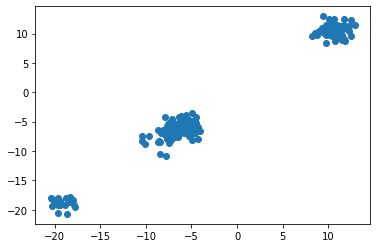

In [ ]:
data = generate_data(alpha=1, n_components=5, k=4, dim=2, cov=np.array([[1.0, 0.0], [0.0, 1.0]]))
plt.scatter(data[:, 0], data[:, 1]);

You need to upload this [data](https://www.dcc.fc.up.pt/~ltorgo/Regression/puma8NH.tgz).

In [ ]:
!tar --extract --file /content/puma8NH.tgz

In [ ]:
!mv /content/Pumadyn/pumadyn-8nh/puma8NH.data /content/Pumadyn/pumadyn-8nh/puma8NH.test /content/
!rm -r Pumadyn

In [ ]:
def load_data(path):
    with open(path) as f:
        data = []
        for line in f.readlines():
            x = line.strip().split()[:8]
            if x:
                data.append(x)
        return np.array(data, float)

def load_robot_data():
    robot_data = np.vstack((load_data('/content/puma8NH.data'), load_data('/content/puma8NH.test')))
    return train_test_split(robot_data, train_size=7000, test_size=250, random_state=1337)

In [ ]:
train, test = load_robot_data()
print(train.shape, test.shape)

(7000, 8) (250, 8)


## VI

In [ ]:
class VI(object):
    """
    Variational Inference algorithm for the Dirichlet Process Mixture Model
    Observed variables of the model : X
    Hidden variables of the model : V, eta* and Z. eta* will be replaced by H in the code.
    We are trying to determine : q(Z,V,H). For the model to be tractable, consider: q(Z,V,H,K)
    """
    def __init__(self, X, alpha, llambda, Sigma, Sigma0, K = 20, dist = "normal"):
        """
        :param X: The observed variables
        :param alpha : alpha of the DP
        :param llambda: lambda in eta*
        :param K: The truncation parameter (variational parameter to be tweaked)
        :param dist: The distribution chosen in the exponential family
        """

        self.X = X
        self.N = X.shape[0]
        self.D = X.shape[1]
        self.K = K
        self.dist = dist
        self.Sigma = Sigma
        self.Sigma0_inv = np.linalg.inv(Sigma0)
        self.Sigma0 = Sigma0

        self.families = {"normal" : multivariate_normal, "beta" : beta, "gamma" : gamma}  #The exponential family is very large, here is only a sample


        #Variational parameters : (_pm used to differentiate distributions from parameters especially for gamma)
        #What initialization to give (for now to 0)?

        self.gamma_pm = np.ones((self.K, 2))
        self.tau1_pm = np.zeros((self.K, self.D))
        self.tau2_pm = np.zeros(self.K)
        self.phi_pm = np.zeros((self.N, self.K))

        self.alpha = alpha
        self.llambda = llambda

    def update(self):
        """Update the values according to the VI inference"""

        #Conjugate setting update for gamma and tau :
        error = 0
        for i in range(self.K-1):
            error += (self.gamma_pm[i,0]- 1 - np.sum(self.phi_pm[:,i]))**2
            error += (self.gamma_pm[i,1]- self.alpha - np.sum([np.sum(self.phi_pm[n,i+1:]) for n in range(self.N)]))**2
            self.gamma_pm[i,0] = 1 + np.sum(self.phi_pm[:,i])
            self.gamma_pm[i,1] = self.alpha + np.sum([np.sum(self.phi_pm[n,i+1:]) for n in range(self.N)])

        for i in range(self.K):
            error += (np.linalg.norm(self.tau1_pm[i] - self.llambda[0] - np.matmul(self.phi_pm[:,i].T, self.X)))**2
            error += (self.tau2_pm[i] - self.llambda[1] - np.sum(self.phi_pm[:,i]))**2
            self.tau1_pm[i] = self.llambda[0] + np.matmul(self.phi_pm[:,i].T, self.X)#np.sum(self.phi_pm[:,i] * self.X, axis=0)
            self.tau2_pm[i] = self.llambda[1] + np.sum(self.phi_pm[:,i])
        #self.error = error
        #Update of the multinomial parameters :

        for i in range(self.K):
            #In order not to recalculate these values for each n :
            E_logV = digamma(self.gamma_pm[i,0]) - digamma(self.gamma_pm[i,0] + self.gamma_pm[i,1])
            E_sum_V = np.sum([digamma(self.gamma_pm[j,1]) - digamma(self.gamma_pm[j,0] + self.gamma_pm[j,1]) for j in range(i-1)])
            E_eta, E_a_eta = self.expectations(i)

            for n in range(self.N):
                self.phi_pm[n,i] = np.exp(E_logV + E_eta.T @ self.X[n] - E_a_eta + E_sum_V)
                #print(E_logV,E_eta.T @ self.X[n],E_a_eta, E_sum_V)

        #Normalization step: the multinomial parameters must sum to 1
        for n in range(self.N):
            #print(np.sum(self.phi_pm[n,:]))
            self.phi_pm[n,:] =  self.phi_pm[n,:]/np.sum(self.phi_pm[n,:])
        return error


    def expectations(self, i):
        """Returns E[eta | tau] and E[a(eta) | tau] """
        if self.dist == "normal":
            Sigma_ = np.linalg.inv(self.tau2_pm[i]*self.Sigma)
            mu_ = np.matmul(Sigma_, self.tau1_pm[i])
            mean = mu_
            a_mean = self.D / (2 * self.tau2_pm[i]) + (np.matmul(np.matmul(mu_.T,self.Sigma),mu_))/2
        return mean, a_mean

    def generate_posterior(self, v, h, z):
        """
        According to the VI algorithm : p( W| X) ~= q(W) with W the hidden variables
        """
        res = 1

        for i in range(self.K-1):
            res *= beta.pdf(v[i], self.gamma_pm[i,0], self.gamma_pm[i,1])

        for i in range(self.K):
            det_Sigma = np.linalg.det(self.Sigma)
            h_eta = (2*np.pi)**(-self.D/2) * det_Sigma**(-1/2) * np.exp(-np.matmul(np.matmul(h[i].T,np.linalg.inv(self.Sigma)),h[i])/2)
            res *= h_eta*np.exp(self.tau1_pm[i].T @ h[i] - self.tau2_pm[i]* (np.matmul(np.matmul(h[i].T,self.Sigma),h[i]))/2 -\
                                (np.matmul(np.matmul(self.tau1_pm[i].T,self.Sigma),self.tau1_pm[i]))/2 )

        for i in range(self.N):
            res *= multinomial.pmf(z[i], n=1, p = self.phi_pm[i]) #z[i] is an array of results encoded as a one-hot vector [0, 0, 1, 0, ..., 0]

        return res


    def run_VI(self, iter = 10, threshold = 0.1):
        """ Run the VI algorithm
        :param iter: The number of iterations
        """
        for i in range(iter):
            err = self.update()
            if err <= threshold:
                print('convergence in iteration %d'%(iter))
                break
            else:
                print(err)


In [ ]:
def exp_a(tau1, tau2, Sigma):
    mat = tau2 * Sigma
    mat_inv = np.linalg.inv(mat)
    res = np.matmul(np.matmul(tau1.T, mat_inv), tau1) / 2
    return np.exp(res)


def held_out_loglikelihood(x, gamma, tau1, tau2, Sigma):
    K = tau1.shape[0]
    d = x.shape[0]
    prob = gamma/np.sum(gamma,axis=1)[:,np.newaxis]
    det_Sigma = np.linalg.det(Sigma)
    Sigma_inv = np.linalg.inv(Sigma)
    h_x = (2*np.pi)**(-d/2) * det_Sigma**(-1/2) * np.exp(-np.matmul(np.matmul(x.T,Sigma_inv),x)/2)
    sum = 0
    for i in range(K):
        if i==0:
            E_theta = prob[i,0]
        else:
            E_theta = prob[i,0] * np.linalg.det(np.diag(prob[:i,1]))
        sum += h_x * E_theta*exp_a(x+tau1[i,:],1+tau2[i], Sigma)/exp_a(tau1[i,:],tau2[i], Sigma)
    return np.log(sum)


In [ ]:
def generate_data(alpha, n_components, k, dim, Sigma, Sigma0, n_samples=100):
    """
    :param alpha : alpha of the DP
    :param n_components: The number of components
    :param k: The truncation parameter (variational parameter to be tweaked)
    :param dim: The dimention of the data
    :param Sigma: The covariance matrix for data x
    :param Sigma0: The covariance matrix for baseline distribution of DP
    :param n_samples: The size of the dataset
    """
    # sample V_i and truncate at K clusters
    v = np.random.beta(1, alpha, n_components)
    v[k:] = 1

    # calculate probabilities
    theta = np.copy(v)
    for i in range(1, n_components):
        theta[i] = theta[i - 1] * v[i] * (1 - v[i - 1]) / v[i - 1]

    # sample means
    eta = np.random.multivariate_normal(np.zeros(dim), Sigma0, n_components)

    # sample components
    components = np.random.choice(n_components, n_samples, p=theta)

    return np.array([np.random.multivariate_normal(eta[c], Sigma) for c in components])

def autocorrelation(c,dim):
    I = np.diag(np.ones(dim))
    corr = np.concatenate([I,np.zeros(dim)[np.newaxis,:]])[1:,:]
    return I + c*corr + c*corr.T



K = 20
alpha = 0.7
dim = 30
n_samples = 200
lambda_1 = np.zeros(dim)
lambda_2 = 2
llambda = (lambda_1,lambda_2)
Sigma = autocorrelation(0.7,dim)
Sigma0 = np.linalg.inv(Sigma)/lambda_2
demo = generate_data(alpha=alpha,n_components=K,k=K,dim=dim,Sigma=Sigma,Sigma0=Sigma0,n_samples=n_samples)


<ipython-input-42-af5e26071f7e>:21: RuntimeWarning: covariance is not positive-semidefinite.
  eta = np.random.multivariate_normal(np.zeros(dim), Sigma0, n_components)
<ipython-input-42-af5e26071f7e>:26: RuntimeWarning: covariance is not positive-semidefinite.
  return np.array([np.random.multivariate_normal(eta[c], Sigma) for c in components])


In [ ]:
trainer = VI(demo[:100,:], alpha, llambda, Sigma, Sigma0, K = K, dist = "normal")
trainer.run_VI(iter=200,threshold=0.01)

81.71000000000001
217555.31397305752
28278.72866859752
34690.5610203921
24387.589523578805
77940.81341408956
92702.9271369319
97223.89375489349
101437.71265093099
105504.74257715631
109157.36866003257
112738.5315583786
115847.19989946812
118382.80326982985
120563.44797429685
122197.12504216729
123530.16253508799
124576.26115185491
125341.61772671602
126031.97057427894
126462.75640371928
126932.93077440551
127174.68582146119
127501.8386987194
127638.0785293209
127868.48754902315
127945.86625067978
128109.07545698107
128153.46869951526
128269.30004416841
128295.07595444297
128377.2692179538
128392.44342478654
128450.69817531532
128459.770758214
128500.99341984537
128506.51013375982
128535.63216879884
128539.04647434456
128559.58809372324
128561.73907588253
128576.20860471104
128577.58710102097
128587.76762925959
128588.66517300699
128595.82115929357
128596.41386519805
128601.43995905737
128601.8361535348
128605.36409602701
128605.63164312438
128608.10677907948
128608.28895935416
128610.0

KeyboardInterrupt: ignored

In [ ]:
loglikelihood = 0
for i in range(100):
    loglikelihood += held_out_loglikelihood(demo[100+i],trainer.gamma_pm,trainer.tau1_pm,trainer.tau2_pm,Sigma)
print(loglikelihood/100)